In [1]:
# PART 2: NUMPY AND PANDAS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Welcome to TrendPulse!")
print("Part 2: NumPy and Pandas")
print("Let's start data analysis!")

Welcome to TrendPulse!
Part 2: NumPy and Pandas
Let's start data analysis!


In [2]:
from google.colab import files

uploaded = files.upload()

print("Files uploaded successfully!")
print(list(uploaded.keys()))

Saving categories.csv to categories.csv
Saving INvideos.csv to INvideos.csv
Saving USvideos.csv to USvideos.csv
Saving GBvideos.csv to GBvideos.csv
Files uploaded successfully!
['categories.csv', 'INvideos.csv', 'USvideos.csv', 'GBvideos.csv']


In [3]:
# Load the three country datasets

us_df = pd.read_csv("USvideos.csv")
gb_df = pd.read_csv("GBvideos.csv")
in_df = pd.read_csv("INvideos.csv")

# Load category lookup
categories_df = pd.read_csv("categories.csv")

# Add country column
us_df["country"] = "US"
gb_df["country"] = "GB"
in_df["country"] = "IN"

# Combine all countries
all_videos = pd.concat(
    [us_df, gb_df, in_df],
    ignore_index=True
)

# Display dataset information
print("US Dataset:", us_df.shape)
print("GB Dataset:", gb_df.shape)
print("IN Dataset:", in_df.shape)

print("\nCombined Dataset:", all_videos.shape)
print("Categories Dataset:", categories_df.shape)

US Dataset: (16080, 17)
GB Dataset: (15075, 17)
IN Dataset: (15075, 17)

Combined Dataset: (46230, 17)
Categories Dataset: (17, 2)


In [4]:
# STEP 4: NUMPY ARRAYS

# Convert columns into numeric values
views = pd.to_numeric(all_videos["views"], errors="coerce").fillna(0).to_numpy()
likes = pd.to_numeric(all_videos["likes"], errors="coerce").fillna(0).to_numpy()
dislikes = pd.to_numeric(all_videos["dislikes"], errors="coerce").fillna(0).to_numpy()
comments = pd.to_numeric(all_videos["comment_count"], errors="coerce").fillna(0).to_numpy()

# Display arrays
print("Views Array:", views[:5])
print("Likes Array:", likes[:5])
print("Dislikes Array:", dislikes[:5])
print("Comments Array:", comments[:5])

print("\nArray shape:", views.shape)
print("Array type:", type(views))

Views Array: [ 48555 198385 231656   8083 373161]
Likes Array: [ 2189.  1159.  8742.   176. 11305.]
Dislikes Array: [180 492 896   8 167]
Comments Array: [ 136. 1446.  432.   19.  891.]

Array shape: (46230,)
Array type: <class 'numpy.ndarray'>


In [5]:
# STEP 5: ENGAGEMENT RATIOS

# Like Ratio
total_ratings = likes + dislikes

like_ratio = np.divide(
    likes,
    total_ratings,
    out=np.zeros_like(likes, dtype=float),
    where=total_ratings != 0
)

# Engagement Rate
engagement_rate = np.divide(
    likes + comments,
    views,
    out=np.zeros_like(views, dtype=float),
    where=views != 0
)

# Display results
print("Like Ratio (First 5):", like_ratio[:5])
print("Engagement Rate (First 5):", engagement_rate[:5])

print("\nAverage Like Ratio:", np.mean(like_ratio))
print("Average Engagement Rate:", np.mean(engagement_rate))

Like Ratio (First 5): [0.92401857 0.70199879 0.90703465 0.95652174 0.98544282]
Engagement Rate (First 5): [0.04788384 0.01313103 0.03960182 0.02412471 0.03268294]

Average Like Ratio: 0.9211539427456944
Average Engagement Rate: 0.03884213005400198


In [6]:
# STEP 6: DATA NORMALIZATION

# Normalize views
min_views = np.min(views)
max_views = np.max(views)

normalized_views = (
    (views - min_views) / (max_views - min_views)
)

# Normalize likes
min_likes = np.min(likes)
max_likes = np.max(likes)

normalized_likes = (
    (likes - min_likes) / (max_likes - min_likes)
)

print("Original Views:", views[:5])
print("Normalized Views:", normalized_views[:5])

print("\nOriginal Likes:", likes[:5])
print("Normalized Likes:", normalized_likes[:5])

print("\nMinimum Normalized View:", np.min(normalized_views))
print("Maximum Normalized View:", np.max(normalized_views))

Original Views: [ 48555 198385 231656   8083 373161]
Normalized Views: [1.31636320e-04 5.46955021e-04 6.39179999e-04 1.94506529e-05
 1.03142236e-03]

Original Likes: [ 2189.  1159.  8742.   176. 11305.]
Normalized Likes: [7.94906729e-05 4.20875696e-05 3.17454300e-04 6.39120988e-06
 4.10526294e-04]

Minimum Normalized View: 0.0
Maximum Normalized View: 1.0


In [7]:
# STEP 7: ENGAGEMENT SCORE

normalized_comments = (
    (comments - np.min(comments)) /
    (np.max(comments) - np.min(comments))
)

engagement_score = (
    normalized_views * 0.4 +
    normalized_likes * 0.4 +
    normalized_comments * 0.2
)

print("Engagement Score (First 5):", engagement_score[:5])

print("\nAverage Engagement Score:", np.mean(engagement_score))
print("Highest Engagement Score:", np.max(engagement_score))
print("Lowest Engagement Score:", np.min(engagement_score))

Engagement Score (First 5): [1.19394720e-04 6.07153156e-04 4.93652062e-04 1.52186167e-05
 8.05713543e-04]

Average Engagement Score: 0.002856413181855698
Highest Engagement Score: 0.953804648055602
Lowest Engagement Score: 6.636539640857968e-07


In [8]:
# STEP 8: NUMPY BROADCASTING

# Add 10 to every video view count
updated_views = views + 10

# Multiply every like count by 2
doubled_likes = likes * 2

print("Original Views:", views[:5])
print("Updated Views:", updated_views[:5])

print("\nOriginal Likes:", likes[:5])
print("Doubled Likes:", doubled_likes[:5])

Original Views: [ 48555 198385 231656   8083 373161]
Updated Views: [ 48565 198395 231666   8093 373171]

Original Likes: [ 2189.  1159.  8742.   176. 11305.]
Doubled Likes: [ 4378.  2318. 17484.   352. 22610.]


In [9]:
# STEP 9: NUMPY RESHAPE AND FLATTEN

# Take the first 10 view counts
sample_views = views[:10]

# Reshape into 2 rows and 5 columns
reshaped_views = sample_views.reshape(2, 5)

print("Original Array:")
print(sample_views)

print("\nReshaped Array:")
print(reshaped_views)

# Flatten the reshaped array
flattened_views = reshaped_views.flatten()

print("\nFlattened Array:")
print(flattened_views)

print("\nOriginal Shape:", sample_views.shape)
print("Reshaped Shape:", reshaped_views.shape)
print("Flattened Shape:", flattened_views.shape)

Original Array:
[  48555  198385  231656    8083  373161  513855  286729 2841278   86190
  518563]

Reshaped Array:
[[  48555  198385  231656    8083  373161]
 [ 513855  286729 2841278   86190  518563]]

Flattened Array:
[  48555  198385  231656    8083  373161  513855  286729 2841278   86190
  518563]

Original Shape: (10,)
Reshaped Shape: (2, 5)
Flattened Shape: (10,)


In [10]:
# STEP 10: PANDAS DATA INSPECTION

print("First 5 Rows:")
display(all_videos.head())

print("\nLast 5 Rows:")
display(all_videos.tail())

print("\nDataset Information:")
all_videos.info()

print("\nStatistical Summary:")
display(all_videos.describe())

print("\nDataset Shape:", all_videos.shape)

print("\nColumn Names:")
print(all_videos.columns.tolist())

First 5 Rows:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,g_N-w8LeAi8,17.14.11,Honest Football Prank LEAKED,QuietSpeech10,22,2017-11-14T07:04:28.000Z,Monsoon|Robots,48555,2189.0,180,136.0,https://i.ytimg.com/vi/g_N-w8LeAi8/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
1,Ugyql2NlPAd,17.14.11,Surprising Cricket Review,IncredibleChallenge41,25,2017-11-12T22:35:48.000Z,Winter,198385,1159.0,492,1446.0,https://i.ytimg.com/vi/Ugyql2NlPAd/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
2,8fE19jkxJ9n,17.14.11,Mira Solis - Football (Live) OFFICIAL,WildTutorial42,10,2017-11-13T08:40:22.000Z,Cricket,231656,8742.0,896,432.0,https://i.ytimg.com/vi/8fE19jkxJ9n/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
3,WOY0nn7HCsO,17.14.11,Zed Rivera - Space (Lyric Video)?!,ShockingInterview30,10,2017-10-27T22:21:47.000Z,Festival|Guitar,8083,176.0,8,19.0,https://i.ytimg.com/vi/WOY0nn7HCsO/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
4,2Lc_Cs5VVr_,17.14.11,Surprising Election Recipe,UltimateVlog96,27,2017-11-09T13:20:20.000Z,Festival,373161,11305.0,167,891.0,https://i.ytimg.com/vi/2Lc_Cs5VVr_/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US



Last 5 Rows:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
46225,GE3gN91ry5r,18.27.01,Shocking Festival Review!,UltimateTrailer12,25,2018-01-24T05:07:49.000Z,Winter|Robots,195070,2052.0,1295,2022.0,https://i.ytimg.com/vi/GE3gN91ry5r/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,IN
46226,sSm2QclhBgY,18.27.01,Perfect Cars Reaction MUST,CrazyRecipe67,23,2018-01-27T10:18:11.000Z,Winter|Pasta,207026,3129.0,169,723.0,https://i.ytimg.com/vi/sSm2QclhBgY/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,IN
46227,Sjafu9aJxnL,18.27.01,Blue Harbor - Winter (Official Video),FinalTrailer17,10,2018-01-27T10:20:56.000Z,Cricket|Festival|Bangalore|Space,246227,5611.0,1053,969.0,https://i.ytimg.com/vi/Sjafu9aJxnL/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,IN
46228,EgKEYJXtt4Y,18.27.01,Quiet Chess Reaction,FinalHighlights33,24,2018-01-27T11:43:05.000Z,Cars|Cats|Festival,129070,5421.0,698,272.0,https://i.ytimg.com/vi/EgKEYJXtt4Y/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,IN
46229,-acPk6aMAql,18.27.01,Final Robots Challenge OFFICIAL,EpicTutorial97,23,2018-01-26T07:55:30.000Z,Cars|Festival|Football,222435,10830.0,427,1667.0,https://i.ytimg.com/vi/-acPk6aMAql/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,IN



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46230 entries, 0 to 46229
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   video_id                46230 non-null  object 
 1   trending_date           46230 non-null  object 
 2   title                   46230 non-null  object 
 3   channel_title           46230 non-null  object 
 4   category_id             46230 non-null  int64  
 5   publish_time            46230 non-null  object 
 6   tags                    46230 non-null  object 
 7   views                   46230 non-null  int64  
 8   likes                   46218 non-null  float64
 9   dislikes                46230 non-null  int64  
 10  comment_count           46194 non-null  float64
 11  thumbnail_link          46230 non-null  object 
 12  comments_disabled       46230 non-null  bool   
 13  ratings_disabled        46230 non-null  bool   
 14  video_error_or_r

,category_id,views,likes,dislikes,comment_count
count,46230.000000,4.623000e+04,4.621800e+04,46230.000000,46194.000000
mean,18.645339,1.178603e+06,4.580005e+04,2325.983625,3449.773347
std,7.646745,5.916188e+06,2.969554e+05,10518.962756,13665.153495
min,1.000000,1.066000e+03,0.000000e+00,0.000000,0.000000
25%,10.000000,1.294632e+05,3.656000e+03,213.000000,404.000000
50%,22.000000,3.182775e+05,1.020100e+04,594.000000,1074.000000
75%,24.000000,8.240505e+05,2.898775e+04,1666.000000,2779.000000
max,28.000000,3.607602e+08,2.753782e+07,618175.000000,778390.000000



Dataset Shape: (46230, 17)

Column Names:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country']


In [11]:
# STEP 11: CHECK MISSING VALUES

missing_values = all_videos.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

print("\nMissing Value Percentage:")
missing_percentage = (missing_values / len(all_videos)) * 100
print(missing_percentage.round(2))

Missing Values in Each Column:
video_id                     0
trending_date                0
title                        0
channel_title                0
category_id                  0
publish_time                 0
tags                         0
views                        0
likes                       12
dislikes                     0
comment_count               36
thumbnail_link               0
comments_disabled            0
ratings_disabled             0
video_error_or_removed       0
description               1624
country                      0
dtype: int64

Total Missing Values:
1672

Missing Value Percentage:
video_id                  0.00
trending_date             0.00
title                     0.00
channel_title             0.00
category_id               0.00
publish_time              0.00
tags                      0.00
views                     0.00
likes                     0.03
dislikes                  0.00
comment_count             0.08
thumbnail_link            0.00
co

In [12]:
# STEP 12: HANDLE MISSING VALUES

cleaned_videos = all_videos.copy()

cleaned_videos["likes"] = cleaned_videos["likes"].fillna(0)
cleaned_videos["comment_count"] = cleaned_videos["comment_count"].fillna(0)
cleaned_videos["description"] = cleaned_videos["description"].fillna("No description")

print("Missing Values After Cleaning:")
print(cleaned_videos.isnull().sum())

print("\nTotal Missing Values After Cleaning:")
print(cleaned_videos.isnull().sum().sum())

Missing Values After Cleaning:
video_id                  0
trending_date             0
title                     0
channel_title             0
category_id               0
publish_time              0
tags                      0
views                     0
likes                     0
dislikes                  0
comment_count             0
thumbnail_link            0
comments_disabled         0
ratings_disabled          0
video_error_or_removed    0
description               0
country                   0
dtype: int64

Total Missing Values After Cleaning:
0


In [13]:
# STEP 13: CHECK DUPLICATE RECORDS

duplicate_count = cleaned_videos.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

# Display duplicate records
duplicates = cleaned_videos[cleaned_videos.duplicated()]

print("\nDuplicate Records:")
display(duplicates.head())

print("\nDataset Shape Before Removing Duplicates:")
print(cleaned_videos.shape)

Total Duplicate Rows: 230

Duplicate Records:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
227,5mZQjUmM993,17.15.11,Incredible Budget Trailer,SurprisingChallenge82,25,2017-10-24T04:17:11.000Z,Pasta|Election,303565,2076.0,1472,3200.0,https://i.ytimg.com/vi/5mZQjUmM993/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
252,2-WgN1OMDpr,17.15.11,Perfect Cars Secret,OfficialReview41,24,2017-11-12T07:25:44.000Z,Space|Monsoon|Phones|Winter,652620,15206.0,1190,1568.0,https://i.ytimg.com/vi/2-WgN1OMDpr/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
729,bMzg4V076SI,17.17.11,Wild Phones Reaction FULL,UltimateUnboxing65,1,2017-11-11T04:47:26.000Z,[none],626068,18395.0,1135,2302.0,https://i.ytimg.com/vi/bMzg4V076SI/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
1360,L8e0D8nU9wg,17.20.11,Epic Budget Interview,AmazingSpeech11,24,2017-11-18T16:23:06.000Z,Robots|Chess,56080,1112.0,73,342.0,https://i.ytimg.com/vi/L8e0D8nU9wg/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
1487,XMVR2BV-8jF,17.21.11,Incredible Guitar Interview?!,UltimateReview56,24,2017-11-19T22:01:11.000Z,Monsoon,158664,4302.0,400,586.0,https://i.ytimg.com/vi/XMVR2BV-8jF/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US



Dataset Shape Before Removing Duplicates:
(46230, 17)


In [14]:
# STEP 14: REMOVE DUPLICATES

cleaned_videos = cleaned_videos.drop_duplicates()

print("Duplicates Removed: 230")

print("\nDataset Shape After Removing Duplicates:")
print(cleaned_videos.shape)

print("\nRemaining Duplicate Rows:")
print(cleaned_videos.duplicated().sum())

Duplicates Removed: 230

Dataset Shape After Removing Duplicates:
(46000, 17)

Remaining Duplicate Rows:
0


In [15]:
# STEP 15: FILTER VIDEOS

# Videos with more than 1 million views
high_view_videos = cleaned_videos[
    cleaned_videos["views"] > 1000000
]

print("Videos with More Than 1 Million Views:")
display(high_view_videos.head(10))

print("\nTotal High-View Videos:")
print(len(high_view_videos))

# Videos with fewer than 100,000 views
low_view_videos = cleaned_videos[
    cleaned_videos["views"] < 100000
]

print("\nTotal Low-View Videos:")
print(len(low_view_videos))

Videos with More Than 1 Million Views:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
7,3KkxacvDZi1,17.14.11,Official Cats Speech EXCLUSIVE,AmazingSecret45,24,2017-11-14T11:04:57.000Z,Cricket|Football|Guitar,2841278,52635.0,7691,12067.0,https://i.ytimg.com/vi/3KkxacvDZi1/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
11,0wJkyWriHku,17.14.11,Surprising Budget Interview WATCH!,Brand NewReview23,24,2017-11-13T14:51:37.000Z,Robots|Football,2855690,160954.0,9170,9876.0,https://i.ytimg.com/vi/0wJkyWriHku/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
13,K6Z7kZ-uFHF,17.14.11,DJ Aster - Festival (Live),WildUnboxing39,10,2017-10-29T05:02:21.000Z,Festival|Minecraft,1905264,75034.0,5722,4491.0,https://i.ytimg.com/vi/K6Z7kZ-uFHF/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
19,m71Nfcuk3ns,17.14.11,Shocking Monsoon Reaction,UltimateReview24,23,2017-11-14T09:23:46.000Z,Election|Cars|Monsoon,1130682,78147.0,745,3983.0,https://i.ytimg.com/vi/m71Nfcuk3ns/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
55,wtMm_-qzmGh,17.14.11,Epic Election Interview,UltimateUnboxing65,1,2017-11-13T20:15:49.000Z,[none],2998582,120472.0,12216,12607.0,https://i.ytimg.com/vi/wtMm_-qzmGh/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
67,BJHG7ZqwQAB,17.14.11,Crazy Football Recipe!,PerfectRecipe71,15,2017-11-14T23:46:51.000Z,[none],1635309,39531.0,459,0.0,https://i.ytimg.com/vi/BJHG7ZqwQAB/default.jpg,True,False,False,Watch this video. Subscribe for more content a...,US
69,PJGgqHiEhYg,17.14.11,Mira Solis - Guitar (Official Video) FULL,FinalTrailer17,10,2017-11-07T07:11:19.000Z,Cats|Robots|Space|Cricket,1624900,69974.0,2562,3814.0,https://i.ytimg.com/vi/PJGgqHiEhYg/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
80,QtX0WIu7nDD,17.14.11,Perfect Election Unboxing,ShockingMystery66,1,2017-11-13T18:33:19.000Z,Cats|Cricket,1304642,22768.0,1196,3252.0,https://i.ytimg.com/vi/QtX0WIu7nDD/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
117,l0ABPBKdj7C,17.14.11,Crazy Paris Trailer,OfficialReview41,24,2017-11-13T23:59:15.000Z,[none],1310040,31104.0,2524,5938.0,https://i.ytimg.com/vi/l0ABPBKdj7C/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
122,SpweCqhJKfl,17.14.11,Nova Kane - Pasta (Lyric Video),ShockingSecret98,10,2017-11-13T21:58:32.000Z,Phones|Space|Budget|Election,3501006,123821.0,7299,0.0,https://i.ytimg.com/vi/SpweCqhJKfl/default.jpg,True,False,False,Watch this video. Subscribe for more content a...,US



Total High-View Videos:
9686

Total Low-View Videos:
8807


In [16]:
# STEP 16: COUNTRY-WISE FILTERING

us_videos = cleaned_videos[cleaned_videos["country"] == "US"]
gb_videos = cleaned_videos[cleaned_videos["country"] == "GB"]
in_videos = cleaned_videos[cleaned_videos["country"] == "IN"]

print("US Videos:", len(us_videos))
print("GB Videos:", len(gb_videos))
print("India Videos:", len(in_videos))

print("\nAverage Views by Country:")
print(cleaned_videos.groupby("country")["views"].mean())

US Videos: 16000
GB Videos: 15000
India Videos: 15000

Average Views by Country:
country
GB    1.584041e+06
IN    9.521008e+05
US    1.013904e+06
Name: views, dtype: float64


In [17]:
# STEP 17: MERGE CATEGORY DATA

# Check category ID data types
print("Video category ID type:", cleaned_videos["category_id"].dtype)
print("Category table ID type:", categories_df["category_id"].dtype)

# Convert both columns to the same type
cleaned_videos["category_id"] = cleaned_videos["category_id"].astype(int)
categories_df["category_id"] = categories_df["category_id"].astype(int)

# Merge datasets
merged_videos = pd.merge(
    cleaned_videos,
    categories_df,
    on="category_id",
    how="left"
)

print("\nMerged Dataset:")
display(merged_videos.head())

print("\nMerged Dataset Shape:", merged_videos.shape)

Video category ID type: int64
Category table ID type: int64

Merged Dataset:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,category_name
0,g_N-w8LeAi8,17.14.11,Honest Football Prank LEAKED,QuietSpeech10,22,2017-11-14T07:04:28.000Z,Monsoon|Robots,48555,2189.0,180,136.0,https://i.ytimg.com/vi/g_N-w8LeAi8/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,People & Blogs
1,Ugyql2NlPAd,17.14.11,Surprising Cricket Review,IncredibleChallenge41,25,2017-11-12T22:35:48.000Z,Winter,198385,1159.0,492,1446.0,https://i.ytimg.com/vi/Ugyql2NlPAd/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,News & Politics
2,8fE19jkxJ9n,17.14.11,Mira Solis - Football (Live) OFFICIAL,WildTutorial42,10,2017-11-13T08:40:22.000Z,Cricket,231656,8742.0,896,432.0,https://i.ytimg.com/vi/8fE19jkxJ9n/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Music
3,WOY0nn7HCsO,17.14.11,Zed Rivera - Space (Lyric Video)?!,ShockingInterview30,10,2017-10-27T22:21:47.000Z,Festival|Guitar,8083,176.0,8,19.0,https://i.ytimg.com/vi/WOY0nn7HCsO/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Music
4,2Lc_Cs5VVr_,17.14.11,Surprising Election Recipe,UltimateVlog96,27,2017-11-09T13:20:20.000Z,Festival,373161,11305.0,167,891.0,https://i.ytimg.com/vi/2Lc_Cs5VVr_/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US,Education



Merged Dataset Shape: (46000, 18)


In [18]:
# STEP 18: CATEGORY-WISE ANALYSIS

category_analysis = (
    merged_videos
    .groupby("category_name")
    .agg(
        total_videos=("video_id", "count"),
        average_views=("views", "mean"),
        total_likes=("likes", "sum")
    )
    .sort_values(by="average_views", ascending=False)
)

print("Category-wise Analysis:")
display(category_analysis)

print("\nTop 5 Categories by Average Views:")
display(category_analysis.head(5))

Category-wise Analysis:


,total_videos,average_views,total_likes
category_name,,,
Music,10310,3.190950e+06,1.391234e+09
Entertainment,12270,9.010256e+05,3.549985e+08
Comedy,3258,6.034757e+05,9.347858e+07
Film & Animation,2297,5.779740e+05,3.948875e+07
People & Blogs,3804,5.512341e+05,7.545390e+07
Gaming,2057,5.096649e+05,4.267713e+07
Sports,1921,3.749782e+05,2.007697e+07
Education,1645,3.627163e+05,2.075270e+07
Science & Technology,1562,3.563504e+05,1.773510e+07



Top 5 Categories by Average Views:


,total_videos,average_views,total_likes
category_name,,,
Music,10310,3.190950e+06,1.391234e+09
Entertainment,12270,9.010256e+05,3.549985e+08
Comedy,3258,6.034757e+05,9.347858e+07
Film & Animation,2297,5.779740e+05,3.948875e+07
People & Blogs,3804,5.512341e+05,7.545390e+07


In [19]:
# STEP 19: COUNTRY-WISE CATEGORY ANALYSIS

country_category = (
    merged_videos
    .groupby(["country", "category_name"])
    .agg(
        total_videos=("video_id", "count"),
        average_views=("views", "mean")
    )
    .sort_values(
        ["country", "average_views"],
        ascending=[True, False]
    )
)

print("Country-wise Category Performance:")
display(country_category)

print("\nTop Category in Each Country:")

top_categories = (
    country_category
    .reset_index()
    .groupby("country")
    .head(1)
)

display(top_categories)

Country-wise Category Performance:


total_videos  average_views
country category_name                                    
GB      Music                         4990   3.728698e+06
        Entertainment                 2826   8.174841e+05
        Film & Animation               710   7.979800e+05
        Comedy                         937   5.046152e+05
        Gaming                         603   4.953667e+05
        People & Blogs                1292   4.381511e+05
        Science & Technology           469   3.329169e+05
        Sports                         676   2.844951e+05
        Pets & Animals                 309   2.750885e+05
        Education                      467   2.576065e+05
        News & Politics                533   2.339759e+05
        Autos & Vehicles               345   2.222824e+05
        Travel & Events                257   2.214955e+05
        Howto & Style                  586   2.183194e+05
IN      Music                         2281   2.449176e+06
        Entertainment                 5093   9.649596e+05
        Comedy                         962   7.221288e+05
        Gaming                         655   5.784763e+05
        People & Blogs                1093   5.619306e+05
        Film & Animation               768   5.519165e+05
        Sports                         583   5.352064e+05
        Education                      619   4.892673e+05
        Science & Technology           543   3.953709e+05
        Pets & Animals                 286   3.850247e+05
        Howto & Style                  530   3.713830e+05
        News & Politics               1138   3.458839e+05
        Autos & Vehicles               259   3.290292e+05
        Travel & Events                190   2.810373e+05
US      Music                         3039   2.864733e+06
        Entertainment                 4351   8.804494e+05
        People & Blogs                1419   6.459572e+05
        Comedy                        1359   5.876463e+05
        Gaming                         799   4.640460e+05
        Film & Animation               819   4.116833e+05
        Pets & Animals                 318   3.905694e+05
        Science & Technology           550   3.378089e+05
        Sports                         662   3.262674e+05
        Howto & Style                  709   3.133379e+05
        Education                      559   3.103929e+05
        Autos & Vehicles               403   2.971328e+05
        News & Politics                751   2.250676e+05
        Travel & Events                262   1.989428e+05


Top Category in Each Country:


,country,category_name,total_videos,average_views
0,GB,Music,4990,3.728698e+06
14,IN,Music,2281,2.449176e+06
28,US,Music,3039,2.864733e+06


In [20]:
# STEP 20: DATE CONVERSION

# Convert trending_date into datetime format
merged_videos["trending_date"] = pd.to_datetime(
    merged_videos["trending_date"],
    format="%y.%d.%m",
    errors="coerce"
)

# Convert publish_time into datetime format
merged_videos["publish_time"] = pd.to_datetime(
    merged_videos["publish_time"],
    errors="coerce",
    utc=True
)

print("Trending Date:")
print(merged_videos["trending_date"].head())

print("\nPublish Time:")
print(merged_videos["publish_time"].head())

print("\nDate Conversion Completed!")

Trending Date:
0   2017-11-14
1   2017-11-14
2   2017-11-14
3   2017-11-14
4   2017-11-14
Name: trending_date, dtype: datetime64[ns]

Publish Time:
0   2017-11-14 07:04:28+00:00
1   2017-11-12 22:35:48+00:00
2   2017-11-13 08:40:22+00:00
3   2017-10-27 22:21:47+00:00
4   2017-11-09 13:20:20+00:00
Name: publish_time, dtype: datetime64[ns, UTC]

Date Conversion Completed!


In [21]:
# STEP 21: TIME TO TREND

merged_videos["time_to_trend_days"] = (
    merged_videos["trending_date"]
    - merged_videos["publish_time"].dt.tz_localize(None)
).dt.total_seconds() / (24 * 60 * 60)

print("Time to Trend (First 10 Videos):")
print(merged_videos["time_to_trend_days"].head(10))

print("\nAverage Time to Trend:")
print(merged_videos["time_to_trend_days"].mean())

print("\nMinimum Time to Trend:")
print(merged_videos["time_to_trend_days"].min())

print("\nMaximum Time to Trend:")
print(merged_videos["time_to_trend_days"].max())

Time to Trend (First 10 Videos):
0    -0.294769
1     1.058472
2     0.638634
3    17.068206
4     4.444213
5    -0.091713
6    -0.399676
7    -0.461771
8     0.289132
9     0.856100
Name: time_to_trend_days, dtype: float64

Average Time to Trend:
4.591883516505636

Minimum Time to Trend:
-0.9998148148148148

Maximum Time to Trend:
46.19299768518518


In [22]:
# STEP 22: HANDLE NEGATIVE TIME VALUES

negative_count = (
    merged_videos["time_to_trend_days"] < 0
).sum()

print("Negative Time Values:", negative_count)

# Create a separate valid time column
merged_videos["valid_time_to_trend"] = (
    merged_videos["time_to_trend_days"].clip(lower=0)
)

print("\nAverage Valid Time to Trend:")
print(merged_videos["valid_time_to_trend"].mean())

print("\nMinimum Valid Time:")
print(merged_videos["valid_time_to_trend"].min())

print("\nMaximum Valid Time:")
print(merged_videos["valid_time_to_trend"].max())

Negative Time Values: 6136

Average Valid Time to Trend:
4.658544804750402

Minimum Valid Time:
0.0

Maximum Valid Time:
46.19299768518518


In [23]:
# STEP 23: VIDEO TRENDING LIFESPAN

video_lifespan = (
    merged_videos
    .groupby(["country", "video_id"])
    .agg(
        first_trending_date=("trending_date", "min"),
        last_trending_date=("trending_date", "max")
    )
    .reset_index()
)

video_lifespan["lifespan_days"] = (
    video_lifespan["last_trending_date"]
    - video_lifespan["first_trending_date"]
).dt.days + 1

print("Video Trending Lifespan:")
display(video_lifespan.head(10))

print("\nAverage Trending Lifespan:")
print(video_lifespan["lifespan_days"].mean())

print("\nMaximum Trending Lifespan:")
print(video_lifespan["lifespan_days"].max())

Video Trending Lifespan:


,country,video_id,first_trending_date,last_trending_date,lifespan_days
0,GB,--UQXlrk5E0,2017-12-25,2017-12-28,4
1,GB,--pb5oKkYrH,2017-12-04,2017-12-07,4
2,GB,-13iTcoyyzU,2018-01-22,2018-01-22,1
3,GB,-1VjLKhzB3I,2017-11-15,2017-11-15,1
4,GB,-1aX3Wk1cJx,2017-11-23,2017-11-26,4
5,GB,-1rsv0uY-8K,2018-01-25,2018-01-27,3
6,GB,-3WfJZgVB5h,2017-12-30,2018-01-02,4
7,GB,-48JdRO2P5_,2017-12-06,2017-12-07,2
8,GB,-5gYZ79gyl-,2018-01-07,2018-01-07,1
9,GB,-5iZ5HWgnCs,2017-11-28,2017-12-01,4



Average Trending Lifespan:
3.0633508201075768

Maximum Trending Lifespan:
29


In [24]:
# STEP 24: COUNTRY-WISE TRENDING LIFESPAN

lifespan_by_country = (
    video_lifespan
    .groupby("country")
    .agg(
        average_lifespan=("lifespan_days", "mean"),
        maximum_lifespan=("lifespan_days", "max"),
        total_videos=("video_id", "count")
    )
    .sort_values(by="average_lifespan", ascending=False)
)

print("Country-wise Trending Lifespan:")
display(lifespan_by_country)

Country-wise Trending Lifespan:


,average_lifespan,maximum_lifespan,total_videos
country,,,
GB,3.673717,29,4113
US,3.157064,25,5068
IN,2.555461,24,5878


In [25]:
# STEP 25: COUNTRY-WISE SUMMARY

country_summary = (
    merged_videos
    .groupby("country")
    .agg(
        total_videos=("video_id", "count"),
        average_views=("views", "mean"),
        average_likes=("likes", "mean"),
        average_comments=("comment_count", "mean"),
        average_engagement=("valid_time_to_trend", "mean")
    )
)

print("Country-wise Summary:")
display(country_summary.round(2))

Country-wise Summary:


,total_videos,average_views,average_likes,average_comments,average_engagement
country,,,,,
GB,15000,1584041.32,65249.49,4048.23,5.28
IN,15000,952100.76,33135.47,3204.61,4.12
US,16000,1013904.38,39550.40,3119.24,4.57


In [26]:
country_summary = country_summary.rename(
    columns={"average_engagement": "average_time_to_trend_days"}
)

display(country_summary.round(2))

,total_videos,average_views,average_likes,average_comments,average_time_to_trend_days
country,,,,,
GB,15000,1584041.32,65249.49,4048.23,5.28
IN,15000,952100.76,33135.47,3204.61,4.12
US,16000,1013904.38,39550.40,3119.24,4.57


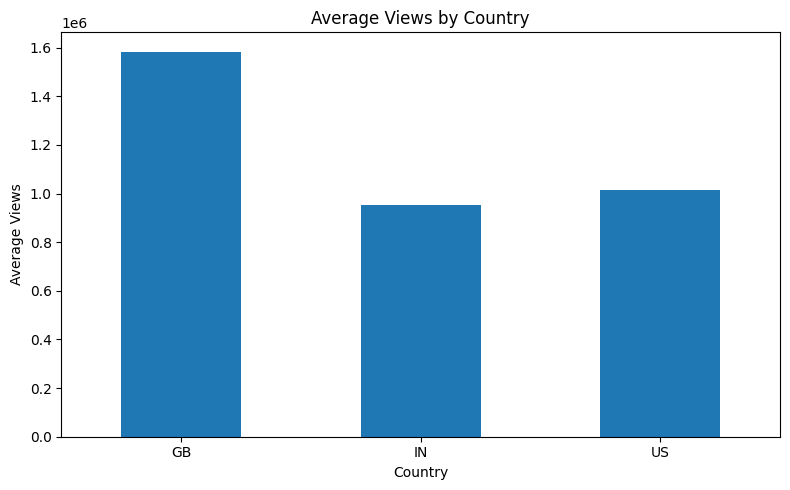

In [27]:
# STEP 26: COUNTRY-WISE AVERAGE VIEWS CHART

country_views = (
    merged_videos.groupby("country")["views"].mean()
)

plt.figure(figsize=(8, 5))

country_views.plot(kind="bar")

plt.title("Average Views by Country")
plt.xlabel("Country")
plt.ylabel("Average Views")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

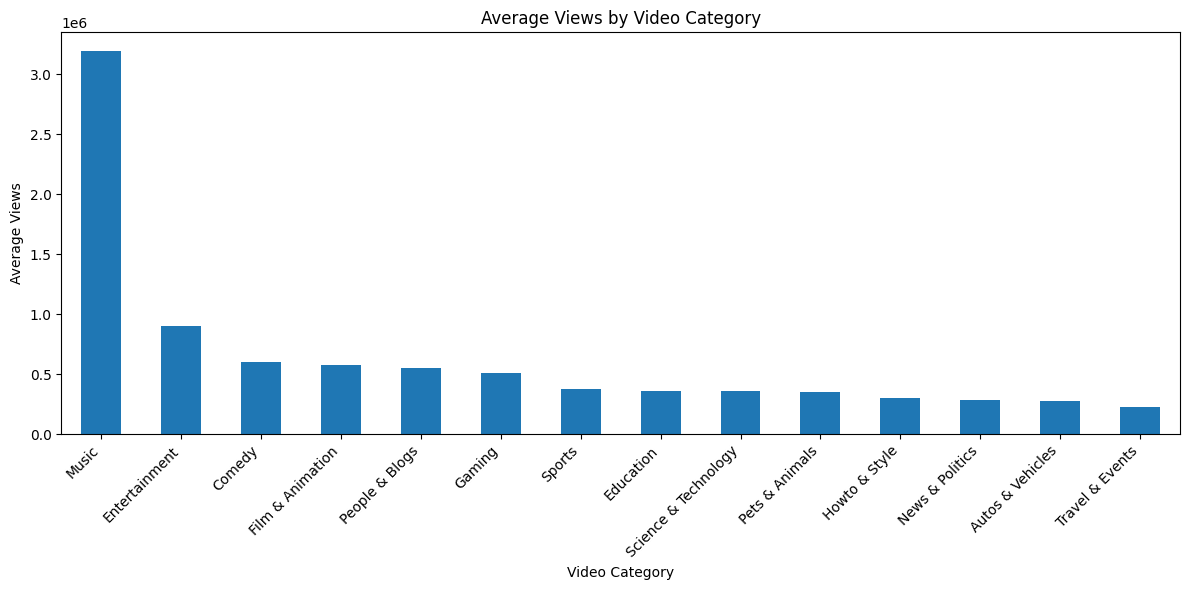

In [28]:
# STEP 27: CATEGORY-WISE AVERAGE VIEWS CHART

category_views = (
    merged_videos
    .groupby("category_name")["views"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

category_views.plot(kind="bar")

plt.title("Average Views by Video Category")
plt.xlabel("Video Category")
plt.ylabel("Average Views")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

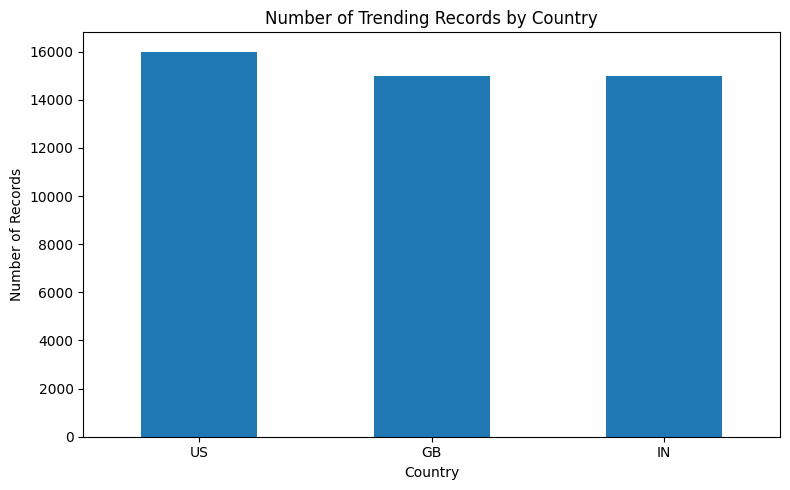

In [29]:
# STEP 28: COUNTRY-WISE VIDEO COUNT CHART

video_counts = merged_videos["country"].value_counts()

plt.figure(figsize=(8, 5))

video_counts.plot(kind="bar")

plt.title("Number of Trending Records by Country")
plt.xlabel("Country")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()